# 04 — ML Feasibility & Experiments

**Goal:** establish whether the dataset supports a defensible prediction task before training models. This notebook deliberately checks target quality and leakage first. It does not promise a high score.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists() and (ROOT.parent / "data" / "raw").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / "dynamic_supply_chain_logistics_dataset.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Open this notebook from the project root "
        "or update DATA_PATH to the CSV location."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)

Dataset shape: (32065, 26)


## 1. Inspect candidate targets

In [3]:
candidate_targets = ["delay_probability", "risk_classification", "disruption_likelihood_score", "delivery_time_deviation", "order_fulfillment_status"]
for col in candidate_targets:
    if col in df.columns:
        print(f"\\n{col}:")
        display(df[col].describe(include="all").to_frame("summary"))

\ndelay_probability:


,summary
count,32065.000000
mean,0.699077
std,0.324514
min,0.000003
25%,0.456009
50%,0.839599
75%,0.982391
max,1.000000


\nrisk_classification:


,summary
count,32065
unique,3
top,High Risk
freq,23944


\ndisruption_likelihood_score:


,summary
count,32065.000000
mean,0.803656
std,0.279185
min,0.000048
25%,0.693739
50%,0.958128
75%,0.998746
max,1.000000


\ndelivery_time_deviation:


,summary
count,32065.000000
mean,5.177648
std,4.157988
min,-1.999998
25%,1.269197
50%,6.113662
75%,9.249206
max,10.000000


\norder_fulfillment_status:


,summary
count,32065.000000
mean,0.600740
std,0.345672
min,0.000001
25%,0.277096
50%,0.680553
75%,0.938160
max,1.000000


## 2. Check risk label against numeric scores

In [4]:
display(df.groupby("risk_classification").agg(
    records=("risk_classification", "size"),
    delay_probability_mean=("delay_probability", "mean"),
    disruption_score_mean=("disruption_likelihood_score", "mean"),
    eta_variation_mean=("eta_variation_hours", "mean")
).round(4))

,records,delay_probability_mean,disruption_score_mean,eta_variation_mean
risk_classification,,,,
High Risk,23944,0.6986,0.9491,2.8960
Low Risk,3110,0.7070,0.1434,2.8834
Moderate Risk,5011,0.6965,0.5186,2.8851


## 3. Correlation with delay probability

In [5]:
corr = df.select_dtypes(include="number").corr()["delay_probability"].drop("delay_probability")
display(corr.reindex(corr.abs().sort_values(ascending=False).index).to_frame("correlation").round(4))

,correlation
fuel_consumption_rate,-0.0137
order_fulfillment_status,0.0097
port_congestion_level,0.0090
disruption_likelihood_score,-0.0082
eta_variation_hours,-0.0069
vehicle_gps_latitude,-0.0062
vehicle_gps_longitude,-0.0057
delivery_time_deviation,0.0055
customs_clearance_time,0.0049
warehouse_inventory_level,0.0047


In [6]:

# Compare potential prediction targets

targets = [
    "delivery_time_deviation",
    "eta_variation_hours",
    "delay_probability",
    "disruption_likelihood_score"
]

for target in targets:
    print(f"\n{'=' * 45}")
    print("TARGET:", target)
    print(df[target].describe().round(3))

    print("Unique values:", df[target].nunique())

    if df[target].nunique() <= 15:
        print(df[target].value_counts().head(15))

# Correlation with potential regression targets
numeric_df = df.select_dtypes(include="number")

for target in targets:
    print(f"\nTop correlations for {target}:")
    correlations = (
        numeric_df.corr()[target]
        .drop(target)
        .sort_values(key=abs, ascending=False)
    )
    print(correlations.head(10).round(3))



TARGET: delivery_time_deviation
count    32065.000
mean         5.178
std          4.158
min         -2.000
25%          1.269
50%          6.114
75%          9.249
max         10.000
Name: delivery_time_deviation, dtype: float64
Unique values: 32065

TARGET: eta_variation_hours
count    32065.000
mean         2.893
std          2.274
min         -2.000
25%          1.186
50%          3.882
75%          4.884
max          5.000
Name: eta_variation_hours, dtype: float64
Unique values: 32065

TARGET: delay_probability
count    32065.000
mean         0.699
std          0.325
min          0.000
25%          0.456
50%          0.840
75%          0.982
max          1.000
Name: delay_probability, dtype: float64
Unique values: 32065

TARGET: disruption_likelihood_score
count    32065.000
mean         0.804
std          0.279
min          0.000
25%          0.694
50%          0.958
75%          0.999
max          1.000
Name: disruption_likelihood_score, dtype: float64
Unique values: 32030

Top

In [8]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Select target
target = "delivery_time_deviation"

# Prepare features
X = df.drop(columns=[target, "timestamp"])
y = df[target]

# Identify column types
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Baseline model
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

# Random Forest
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Evaluation
def evaluate(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

results = pd.DataFrame([
    evaluate("Dummy Baseline", y_test, baseline_predictions),
    evaluate("Random Forest", y_test, predictions)
])

display(results.round(4))


,Model,MAE,RMSE,R2
0,Dummy Baseline,3.7048,4.1527,-0.0000
1,Random Forest,3.7071,4.1596,-0.0033


anomaly_status
Normal     30461
Anomaly     1604
Name: count, dtype: int64


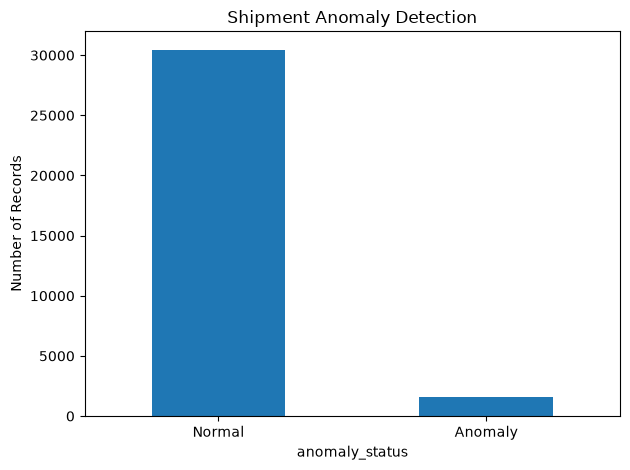

In [9]:

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

features = [
    "iot_temperature",
    "eta_variation_hours",
    "port_congestion_level",
    "fuel_consumption_rate",
    "traffic_congestion_level",
    "supplier_reliability_score",
    "driver_behavior_score",
    "fatigue_monitoring_score",
    "warehouse_inventory_level"
]

X_anomaly = df[features].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_anomaly)

# Train Isolation Forest
iso_model = IsolationForest(
    contamination=0.05,
    random_state=42,
    n_estimators=100
)

df["anomaly"] = iso_model.fit_predict(X_scaled)

# -1 = anomaly, 1 = normal
df["anomaly_status"] = df["anomaly"].map({
    -1: "Anomaly",
    1: "Normal"
})

print(df["anomaly_status"].value_counts())

# Visualize
df["anomaly_status"].value_counts().plot(
    kind="bar",
    title="Shipment Anomaly Detection",
    ylabel="Number of Records"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [10]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.incident_engine import get_incident_report

# Get SOP incident records
incident_report = get_incident_report(df)

# Unique records flagged by SOP rules
sop_records = set(incident_report["record_id"].unique())

# Records flagged by Isolation Forest
anomaly_records = set(
    df.index[df["anomaly"] == -1]
)

# Compare
overlap = anomaly_records & sop_records

print("Total records:", len(df))
print("ML anomalies:", len(anomaly_records))
print("SOP-flagged records:", len(sop_records))
print("Records flagged by both:", len(overlap))
print("ML anomalies also flagged by SOP:", round(
    len(overlap) / len(anomaly_records) * 100, 2
), "%")

Total records: 32065
ML anomalies: 1604
SOP-flagged records: 31769
Records flagged by both: 1593
ML anomalies also flagged by SOP: 99.31 %


In [11]:
# Find records flagged by ML but not by SOP

ml_only = df.loc[
    df.index.isin(anomaly_records - sop_records)
]

print("ML-only anomalies:", len(ml_only))

display(
    ml_only[
        features + ["risk_classification", "delay_probability"]
    ].head(20)
)

# Compare feature averages: anomalies vs normal records

comparison = df.groupby("anomaly_status")[features].mean().T

display(comparison.round(3))

ML-only anomalies: 11


,iot_temperature,eta_variation_hours,port_congestion_level,fuel_consumption_rate,traffic_congestion_level,supplier_reliability_score,driver_behavior_score,fatigue_monitoring_score,warehouse_inventory_level,risk_classification,delay_probability
6415,3.013384,4.021449,3.132348,7.376526,1.482646,0.040244,0.999712,0.077585,999.715120,Moderate Risk,0.999972
11008,0.157592,-1.424823,0.748202,13.225169,7.649531,0.857524,0.862437,0.038894,470.463050,Low Risk,0.765295
11457,2.138313,3.861567,4.040129,19.608898,0.290075,0.381206,1.000000,0.994935,775.780974,High Risk,0.053126
15379,0.626114,4.988633,0.156999,19.692678,0.000672,0.801213,0.448856,0.278830,72.268126,Low Risk,0.999933
17353,1.131026,1.828468,3.488521,19.445724,9.980852,0.062948,0.214511,0.233239,14.317418,High Risk,0.528951
19567,3.940834,3.553107,0.090988,12.280601,0.582629,0.583611,0.987175,0.397682,956.746382,Moderate Risk,0.640410
20366,1.488575,4.612085,0.504395,7.592372,0.354517,0.683510,0.090411,0.156124,977.405910,High Risk,0.110574
24428,1.757358,2.065301,0.020162,19.973863,7.631650,0.738112,0.004151,0.651228,996.333646,High Risk,0.576659
24477,3.731787,-1.215095,1.161354,10.817805,2.092500,0.093419,0.911612,0.263758,306.520517,Low Risk,0.949481
27652,0.453145,-0.959981,0.110487,13.995495,3.835777,0.178417,0.282036,0.107627,634.762383,High Risk,0.308368


anomaly_status,Anomaly,Normal
iot_temperature,21.816,-1.102
eta_variation_hours,1.864,2.947
port_congestion_level,4.473,7.110
fuel_consumption_rate,12.989,7.750
traffic_congestion_level,4.766,5.003
supplier_reliability_score,0.501,0.501
driver_behavior_score,0.550,0.496
fatigue_monitoring_score,0.495,0.606
warehouse_inventory_level,482.325,289.615
